# GPU inference · CPU/CUDA

Chỉ đọc kết quả đã lưu và hiển thị biểu đồ. Không nạp model, không train, không gọi API. Sáu audio phát triển; tỷ lệ tăng tốc từng model không phải tốc độ toàn pipeline.

In [1]:
from pathlib import Path
import json, sys
from IPython.display import display, Markdown, Image, HTML
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from scripts.report_gpu_inference import load_results
OUT = ROOT / 'data/generated/gpu-inference-v1'
bundle = load_results(OUT)
display(Markdown('**6 audio · CPU và CUDA đã hoàn thành.** Không có training hoặc API trả phí.'))

**6 audio · CPU và CUDA đã hoàn thành.** Không có training hoặc API trả phí.

whisper CPU: 17.134 s; CUDA: 2.727 s; speedup: 6.283 x
phoneme-B CPU: 7.8587 s; CUDA: 0.4822 s; speedup: 16.298 x


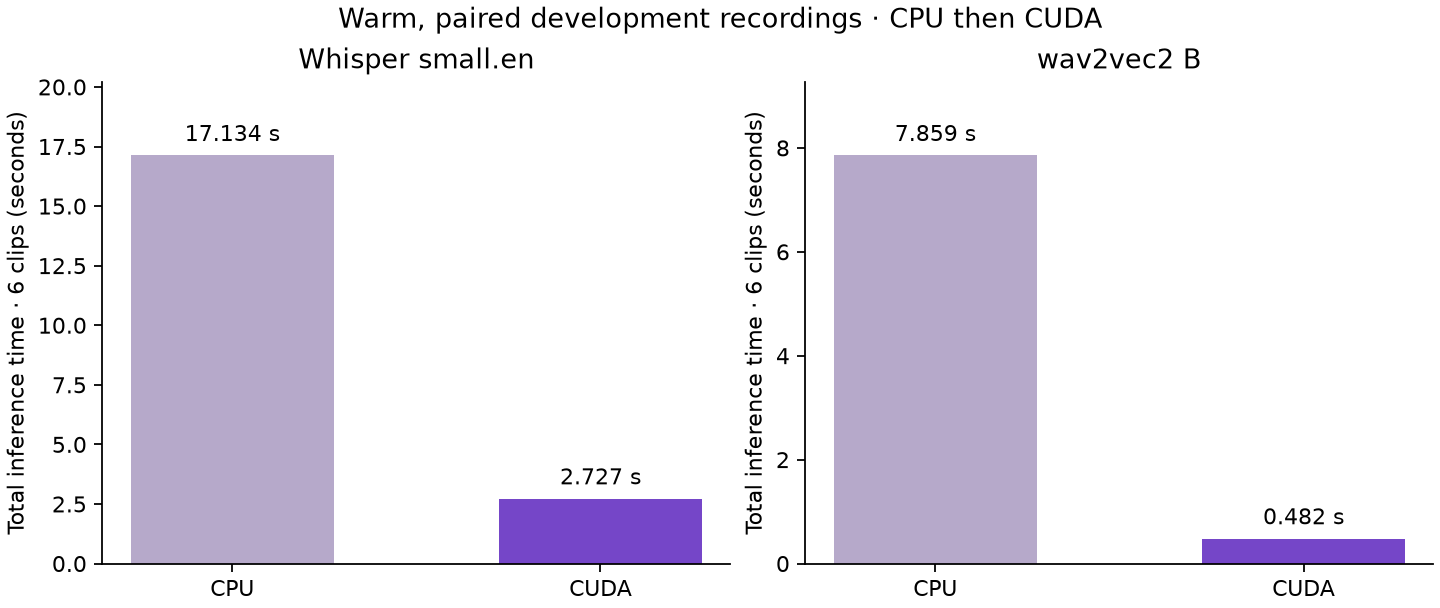

In [2]:
summary = bundle['models']['summaries']
for key in ('whisper', 'phoneme-B'):
    print(key, 'CPU:', summary[key+'-cpu']['total_sec'], 's; CUDA:', summary[key+'-cuda']['total_sec'], 's; speedup:', summary[key+'-speedup'], 'x')
display(Image(filename=str(OUT / 'cpu_cuda_latency.png')))

In [3]:
cpu = {r['id']: r for r in bundle['models']['predictions']['whisper-cpu']}
gpu = {r['id']: r for r in bundle['models']['predictions']['whisper-cuda']}
for key in bundle['models']['text_changes_cpu_cuda']:
    print(key, '\nCPU: ', cpu[key]['text'], '\nCUDA:', gpu[key]['text'], '\n')
print('B phone-sequence changes:', bundle['models']['phone_changes_cpu_cuda'])

TLV-arctic_a0507 
CPU:  In short, my choice as individualism will dominate by author of bourgeois ethics. 
CUDA: In short, my choices in individualism were dominated by author of bourgeois ethics. 

TLV-arctic_a0398 
CPU:  in the car were a Gwen and Harrison white John's sash with the Jaffa 
CUDA: in the car were a Gwynne and Harrison why John sat with the jumper 

user-stella 
CPU:  Please call Stella. Ask her to bring lee things with her from the store. 6 spoons of fresh no peas, 5 thick slabs of blue cheese, and maybe a snack for her brother bowl. You also need a small plastic snack and a big toy fork for the keys. She can scoop lee things into 3 red bags and we will go meet her Wednesday at the train station. 
CUDA: Please call Stella. Ask her to bring lee things with her from the store. 6 spoons of fresh no peas, 5 thick slabs of blue cheese and maybe a snack for her brother ball. You also need a small plastic snack and a big toy frog for the keys. She can scoop lee things into 3 

In [4]:
live = bundle['live']
for job in live['jobs']:
    print(job['case'], job['pronunciation_model'], 'reply / voice / full (s):', job['reply_sec'], job['voice_ready_sec'], job['full_elapsed_sec'])
    print('ASR:', job['asr_runtime']['device'], job['asr_runtime']['compute_type'])
    print('Pronunciation:', job['pronunciation_runtime'])
print('Observed live peak VRAM:', live['observed_peak_gpu_used_mib'], 'MiB')
print('B default restored:', live['default_B_restored'])

user-road cascade-B reply / voice / full (s): 4.5 5.156 7.453
ASR: cuda int8_float16
Pronunciation: {'requested_device': 'auto', 'requested_compute_type': 'auto', 'device': 'cuda:0', 'compute_type': 'float16', 'fallback_reason': None}
user-stella cascade-B reply / voice / full (s): 3.672 4.172 15.297
ASR: cuda int8_float16
Pronunciation: {'requested_device': 'auto', 'requested_compute_type': 'auto', 'device': 'cuda:0', 'compute_type': 'float16', 'fallback_reason': None}
TLV-arctic_a0018 crottc-if-l2-arctic reply / voice / full (s): 1.14 1.64 18.015
ASR: cuda int8_float16
Pronunciation: {'requested_device': 'auto', 'device': 'cpu', 'effective_device': 'cpu', 'compute_type': 'float32', 'device_fallback_reason': 'insufficient_free_cuda_memory', 'min_free_cuda_mib': 2560, 'cuda_free_mib': 2344.5, 'cuda_total_mib': 4095.6, 'cuda_memory_gate_source': 'min_torch_and_nvidia_smi', 'cuda_physical_free_mib': 868, 'cuda_physical_total_mib': 4096, 'cuda_memory_gate_free_mib': 868.0, 'cpu_threads': 

In [5]:
display(HTML((OUT / 'report.html').read_text(encoding='utf-8')))
print('Input SHA256:', bundle['sha256'])

Input SHA256: {'models': '3437506d22196df022281c428cf6d27125b5af291e626b9a324d96cf0e26b3b0', 'live': '8e912577bcc49626e149788454d68dda198cdf1cfb516a3449fff2a73a46db06'}
